# AF 3: Introducción al Aprendizaje Máquina — Aplicación de Clustering (K-Means)

**Universidad Autónoma de Nuevo León (UANL) — Facultad de Ingeniería Mecánica y Eléctrica (FIME)**  
**Unidad de Aprendizaje:** Introducción a la Inteligencia Artificial / Introducción al Aprendizaje Máquina  
**Dataset:** [Stroke Prediction Dataset (Kaggle — `fedesoriano/stroke-prediction-dataset`)](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Xraight/FIME-Machine-Learning-/blob/main/AF3/AF3.ipynb)

---

### Estructura de la Actividad Fundamental 3
1. **Sección 1 — Preparación y Escalado de Características para Distancias:** Carga del dataset limpio de la AF1 (imputación de `bmi` con la mediana), **eliminación estricta de `id` y de la variable objetivo `stroke`**, selección de variables continuas clave (`age`, `avg_glucose_level`, `bmi`), estandarización con `StandardScaler` y análisis matemático de la sensibilidad de K-Means a la escala.
2. **Sección 2 — Búsqueda del Número Óptimo de Clústeres:** Aplicación del **Método del Codo (Inercia / WCSS)** para $k \in [1, 10]$ y del **Coeficiente de Silueta (Silhouette Score)** para $k \in [2, 10]$, justificando matemática y clínicamente la elección del número óptimo de perfiles ($k = 4$, comparado también con $k = 3$).
3. **Sección 3 — Entrenamiento del Modelo y Visualización de Centroides:** Ajuste final de `KMeans`, interpretación física de los centroides en unidades reales (años, $	ext{mg/dL}$, $	ext{kg/m}^2$), gráfico de dispersión **Edad vs. Glucosa** con centroides marcados con **`"X"`**, y proyección 2D mediante **PCA**.
4. **Sección 4 — Validación Cruzada Externa con `stroke`:** Reincorporación de la etiqueta `stroke`, tabla cruzada (`pd.crosstab`) en conteos y porcentajes, visualización de prevalencia de derrame cerebral por clúster y discusión crítica final.

In [1]:
# ==============================================================================
# 0. Configuración del Entorno e Importación de Librerías
# ==============================================================================
import json
import os
import subprocess
import sys
from pathlib import Path

try:
    import kagglehub
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 220,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "font.size": 10,
})
sns.set_style("whitegrid")

# Directorios de salida compatibles con ejecución desde raíz o dentro de AF3/
CWD = Path.cwd()
AF3_ROOT = CWD if CWD.name == "AF3" else (CWD / "AF3" if (CWD / "AF3").exists() else CWD)
OUTPUT_DIR = AF3_ROOT / "outputs"
REPORT_FIG_DIR = AF3_ROOT / "report" / "Imágenes"
FIG_DIR = REPORT_FIG_DIR if REPORT_FIG_DIR.exists() else (OUTPUT_DIR / "figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f" Semilla experimental : SEED = {SEED}")
print(f" Directorio de figuras: {FIG_DIR}")

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


 Semilla experimental : SEED = 42
 Directorio de figuras: /workspace/AF3/report/Imágenes


### Análisis de Configuración
Se inicializó el entorno científico con `numpy`, `pandas`, `matplotlib`, `seaborn` y `scikit-learn` (`StandardScaler`, `KMeans`, `silhouette_score`, `PCA`), fijando la semilla `SEED = 42` para garantizar que la inicialización `k-means++` de los centroides sea 100% reproducible en Google Colab y en Docker.

---
## Sección 1: Preparación y Escalado de Características para Distancias

**Objetivo:** Comprender por qué los algoritmos de clustering basados en distancias euclidianas (como K-Means) exigen un preprocesamiento y estandarización estrictos, garantizando además que el modelo opere en un régimen puramente **no supervisado** (sin acceso a `stroke` ni `id`).

In [2]:
# ==============================================================================
# 1.1 Carga del Dataset, Limpieza (AF1) y Separación Estricta de 'stroke' e 'id'
# ==============================================================================
dataset_dir = Path(kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset"))
csv_files = list(dataset_dir.glob("*.csv"))
assert len(csv_files) > 0, f"No se encontró archivo CSV en {dataset_dir}"
df_raw = pd.read_csv(csv_files[0])

print(f"Registros totales cargados: {df_raw.shape[0]} | Columnas originales: {df_raw.shape[1]}")
print(f"Valores nulos originales en 'bmi': {int(df_raw['bmi'].isna().sum())}")

# Limpieza heredada de AF1: imputación de 'bmi' con la mediana para conservar todos los pacientes
df_clean = df_raw.copy()
bmi_median = float(df_clean["bmi"].median())
df_clean["bmi"] = df_clean["bmi"].fillna(bmi_median)

# Guardar la etiqueta real 'stroke' por separado EXCLUSIVAMENTE para la Sección 4
y_stroke_real = df_clean["stroke"].copy()

# Eliminar explícitamente la columna objetivo 'stroke' y el identificador 'id'
df_unsupervised = df_clean.drop(columns=["id", "stroke"])
assert "stroke" not in df_unsupervised.columns and "id" not in df_unsupervised.columns

# Selección de las variables numéricas continuas clave
FEATURES = ["age", "avg_glucose_level", "bmi"]
X_raw = df_unsupervised[FEATURES].copy()

# Aplicación de StandardScaler (media = 0, desviación estándar = 1)
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X_raw)
X_scaled = pd.DataFrame(X_scaled_array, columns=FEATURES, index=X_raw.index)

# Comparativa estadística antes y después del escalado
stats_before = X_raw.agg(["min", "max", "mean", "std", "var"]).T
stats_before.columns = ["Mín", "Máx", "Media", "Desv. Est.", "Varianza (Sin Escalar)"]
stats_after = X_scaled.agg(["mean", "std", "var"]).T
stats_after.columns = ["Media (Escalada)", "Desv. Est. (Escalada)", "Varianza (Escalada)"]

comparison_table = pd.concat([stats_before, stats_after], axis=1)
print("\n--- Comparativa Estadística Antes vs. Después de StandardScaler ---")
display(comparison_table.round(3)) if "display" in globals() else print(comparison_table.round(3))

  0%|          | 0.00/67.4k [00:00<?, ?B/s]

100%|██████████| 67.4k/67.4k [00:00<00:00, 823kB/s]

Extracting files...


Registros totales cargados: 5110 | Columnas originales: 12
Valores nulos originales en 'bmi': 201

--- Comparativa Estadística Antes vs. Después de StandardScaler ---
                     Mín     Máx    Media  Desv. Est.  Varianza (Sin Escalar)  \
age                 0.08   82.00   43.227      22.613                 511.332   
avg_glucose_level  55.12  271.74  106.148      45.284                2050.601   
bmi                10.30   97.60   28.862       7.700                  59.283   

                   Media (Escalada)  Desv. Est. (Escalada)  \
age                             0.0                    1.0   
avg_glucose_level               0.0                    1.0   
bmi                            -0.0                    1.0   

                   Varianza (Escalada)  
age                                1.0  
avg_glucose_level                  1.0  
bmi                                1.0  


### Análisis Estadístico y Respuesta a la Pregunta de Investigación (Sección 1)

La tabla superior revela por qué el escalado es indispensable antes de ejecutar K-Means:
- Sin escalar, `avg_glucose_level` abarca de **`55.12` a `271.74` mg/dL** con una **varianza de `2,050.60`**, mientras que `age` tiene una varianza de **`511.33`** (`0.08` a `82.00` años) y `bmi` una varianza de tan solo **`59.25`** (`10.30` a `97.60` $\text{kg/m}^2$).
- Es decir, la varianza de la glucosa es **4 veces mayor que la de la edad** y **34.6 veces mayor que la del IMC**.

> **Pregunta de Investigación (Sección 1):** *¿Por qué si una variable está en años (0 a 100) y otra en miligramos por decilitro (50 a 300) el algoritmo de K-Means fallaría catastróficamente si no se escalan los datos?*
>
> **Respuesta fundamentada:**
> 1. **Dominancia en la distancia euclidiana:** K-Means asigna cada paciente $\mathbf{x}_i$ al centroide $\boldsymbol{\mu}_c$ más cercano minimizando la suma de distancias euclidianas al cuadrado (inercia):
>    $$\|\mathbf{x}_i - \boldsymbol{\mu}_c\|_2^2 = (x_{i,\text{edad}} - \mu_{c,\text{edad}})^2 + (x_{i,\text{glucosa}} - \mu_{c,\text{glucosa}})^2 + (x_{i,\text{bmi}} - \mu_{c,\text{bmi}})^2$$
> 2. **Asimetría de unidades físicas:** Una diferencia clínica moderada de $100\text{ mg/dL}$ en glucosa aporta $100^2 = 10,000$ a la distancia cuadrática, mientras que una diferencia extrema de $20\text{ kg/m}^2$ en IMC (pasar de peso normal a obesidad mórbida) aporta apenas $20^2 = 400$ ($25$ veces menos peso matemático).
> 3. **Colapso geométrico de las fronteras de Voronoi:** Sin `StandardScaler`, los contornos de datos son elipsoides altamente alargados sobre el eje de glucosa, pero K-Means asume clústeres esféricos de varianza isotrópica. Como consecuencia, el algoritmo **ignora prácticamente el IMC y subestima la edad**, particionando a los pacientes casi exclusivamente en franjas horizontales de glucosa. Al aplicar `StandardScaler` ($z = (x - \mu)/\sigma$), las tres variables pasan a tener media $0$ y varianza unitaria ($1.000$), otorgando a la edad, la glucosa y el IMC el mismo peso geométrico inicial.

/tmp/ipykernel_2/2612653669.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Edad (años)", "Glucosa (mg/dL)", "IMC (kg/m²)"])
/tmp/ipykernel_2/2612653669.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["Edad (Z)", "Glucosa (Z)", "IMC (Z)"])


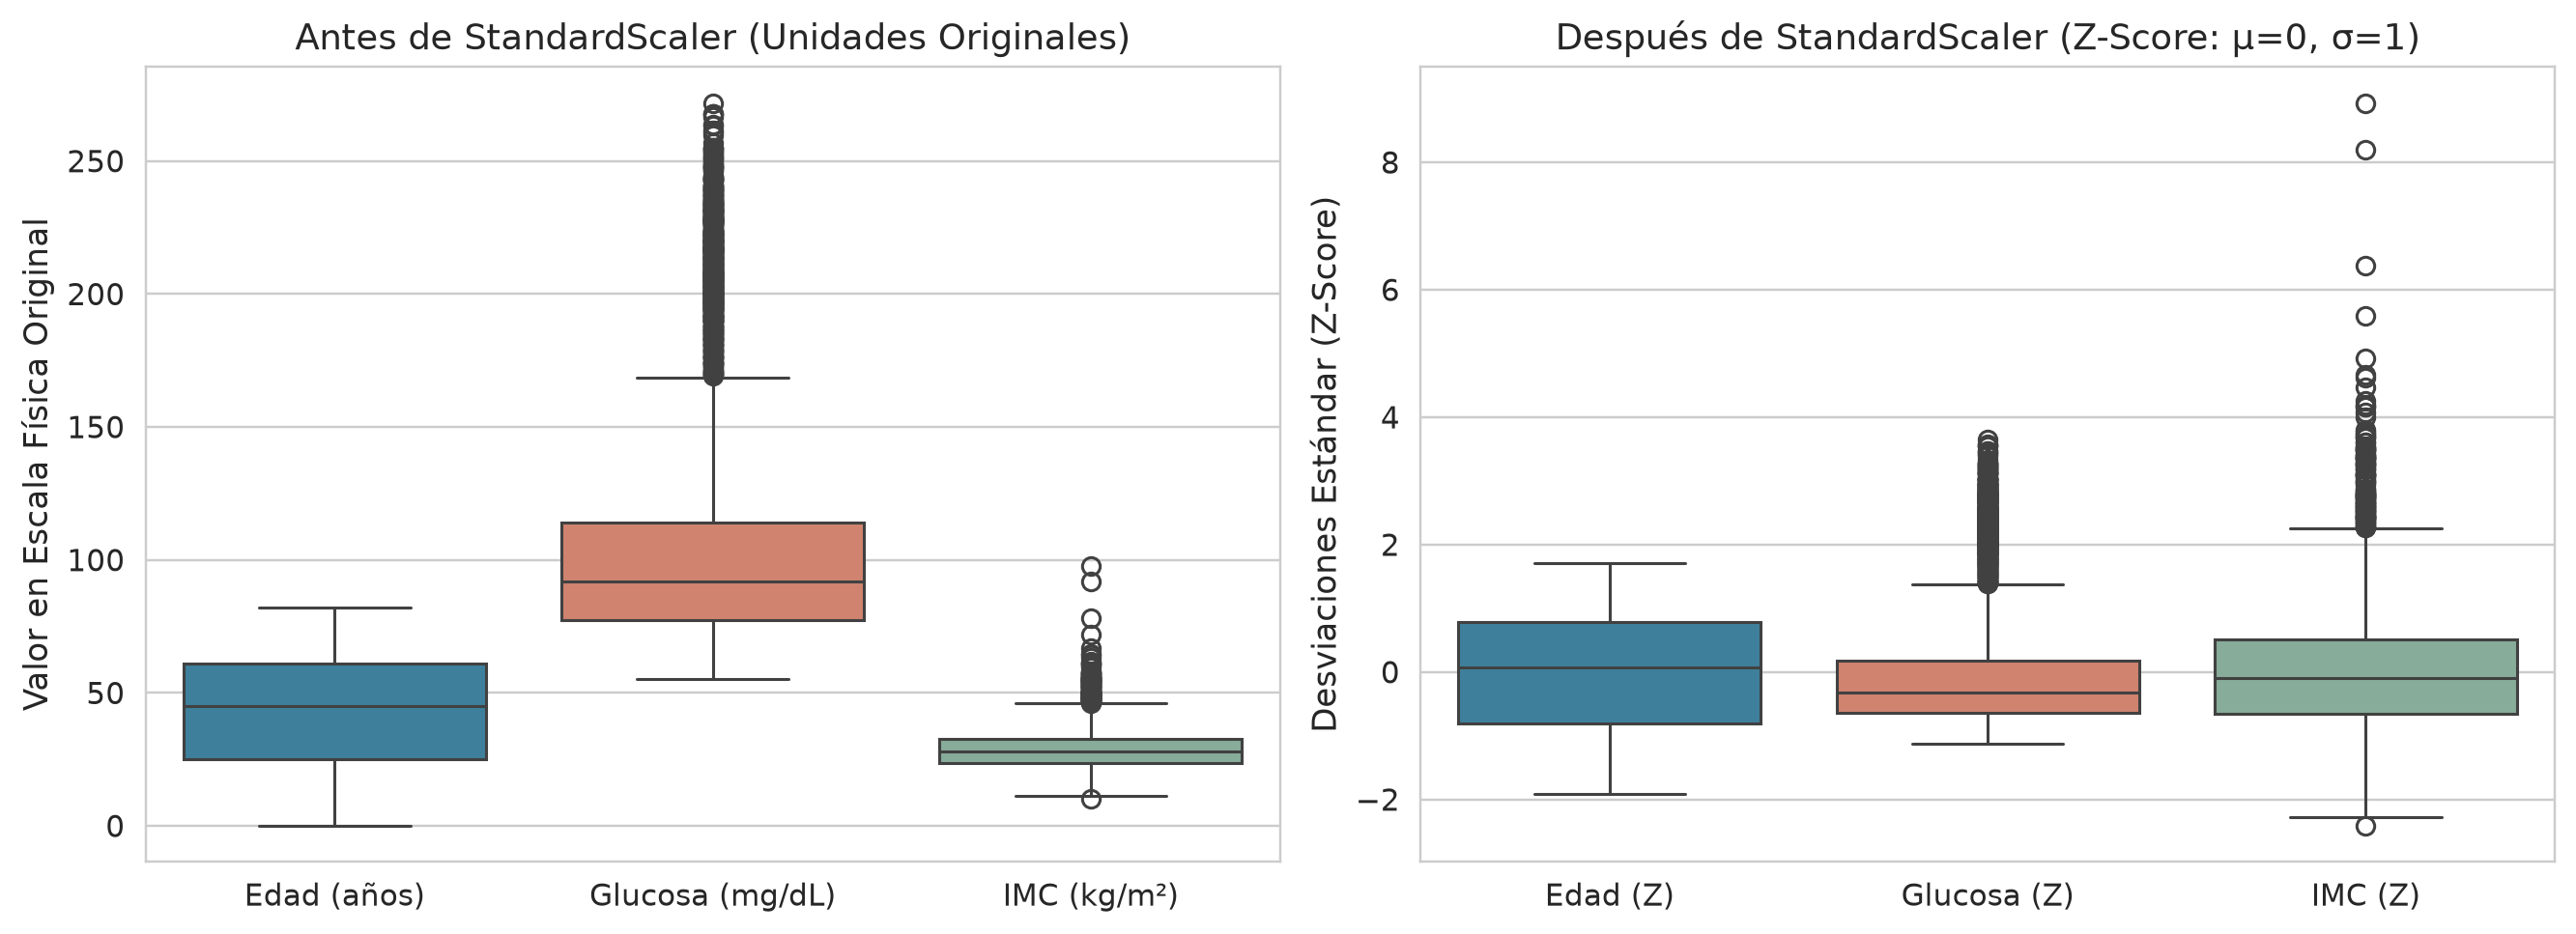

In [3]:
# ==============================================================================
# 1.2 Visualización del Efecto de StandardScaler sobre las Variables Continuas
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.5))

sns.boxplot(data=X_raw, ax=axes[0], palette=["#2E86AB", "#E07A5F", "#81B29A"])
axes[0].set_title("Antes de StandardScaler (Unidades Originales)")
axes[0].set_ylabel("Valor en Escala Física Original")
axes[0].set_xticklabels(["Edad (años)", "Glucosa (mg/dL)", "IMC (kg/m²)"])

sns.boxplot(data=X_scaled, ax=axes[1], palette=["#2E86AB", "#E07A5F", "#81B29A"])
axes[1].set_title("Después de StandardScaler (Z-Score: μ=0, σ=1)")
axes[1].set_ylabel("Desviaciones Estándar (Z-Score)")
axes[1].set_xticklabels(["Edad (Z)", "Glucosa (Z)", "IMC (Z)"])

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_af3_escalado.png", bbox_inches="tight")
plt.show()

### Interpretación Visual del Escalado
En la gráfica izquierda se aprecia cómo la escala de `avg_glucose_level` (con valores de hasta `271.74 mg/dL`) eclipsa numéricamente a `age` y `bmi`. En la gráfica derecha, tras aplicar `StandardScaler`, las tres distribuciones quedan centradas en `0` y expresadas en unidades adimensionales de desviación estándar (*Z-score*), preservando intacta la forma de cada distribución (incluyendo la cola derecha de pacientes con hiperglucemia e IMC elevado) sin distorsionar las distancias entre perfiles clínicos.

---
## Sección 2: Búsqueda del Número Óptimo de Clústeres (Método del Codo y Silueta)

**Objetivo:** Determinar matemáticamente cuántos perfiles naturales de pacientes existen en el espacio fisiológico `(age, avg_glucose_level, bmi)` evaluando:
1. **Método del Codo (Inercia / WCSS)** para $k \in \{1, 2, \dots, 10\}$.
2. **Coeficiente de Silueta (Silhouette Score)** para $k \in \{2, 3, \dots, 10\}$ *(nota: para $k=1$ el coeficiente de silueta no está definido matemáticamente porque requiere calcular la distancia media $b(i)$ al clúster vecino más cercano)*.

Tabla de Evaluación para Selección de k:
   k (Clústeres)  Inercia (WCSS)  Reducción % Inercia  Coeficiente de Silueta
0              1      15330.0000               0.0000                     NaN
1              2      10386.7472              32.2456                  0.3002
2              3       6813.6829              34.4002                  0.3714
3              4       5140.2909              24.5593                  0.3727
4              5       4387.4493              14.6459                  0.3231
5              6       3979.9768               9.2872                  0.3117
6              7       3610.5430               9.2823                  0.2828
7              8       3304.1834               8.4851                  0.2835
8              9       3041.8808               7.9385                  0.2899
9             10       2807.3967               7.7085                  0.2781


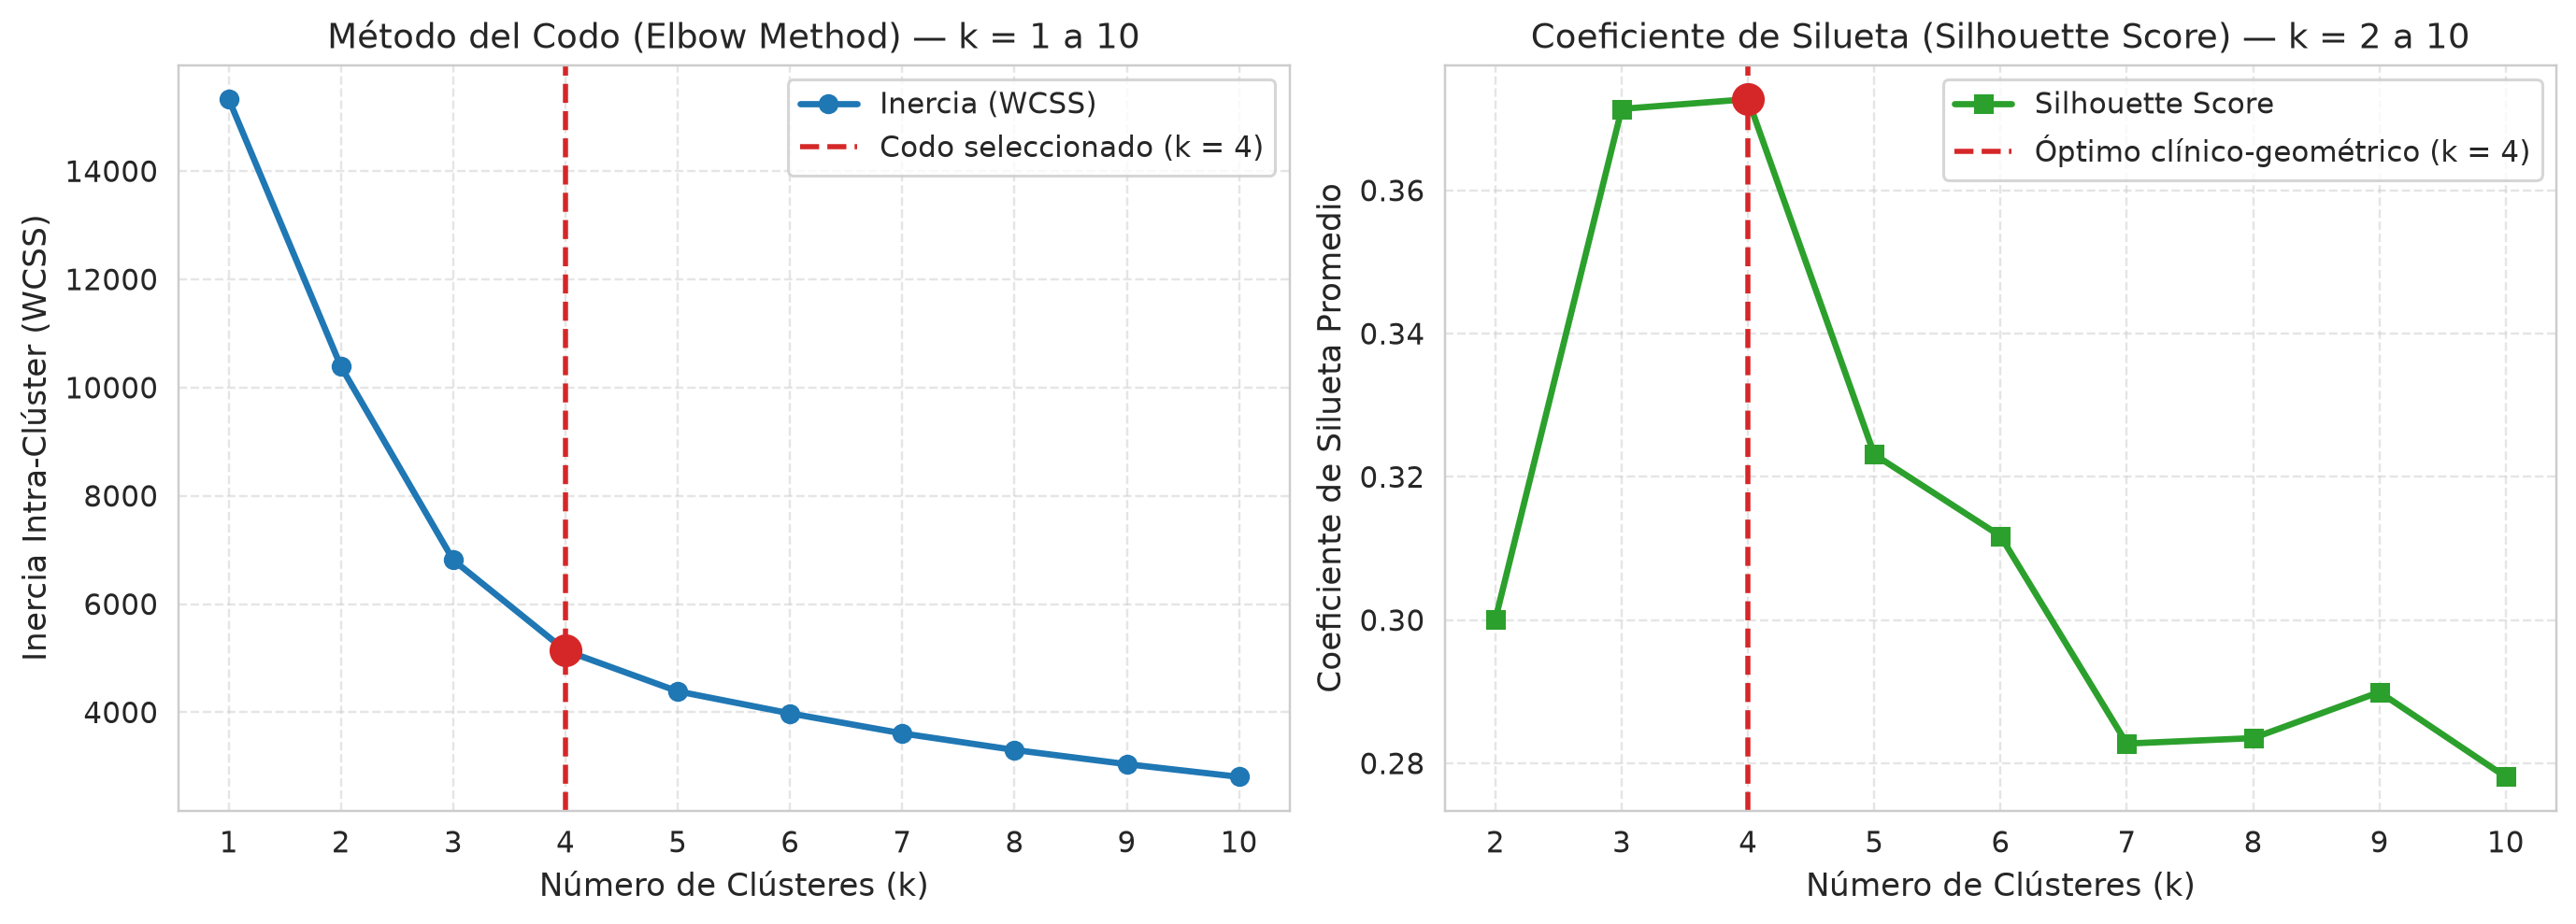

In [4]:
# ==============================================================================
# 2.1 Cálculo de Inercia (k=1..10) y Coeficiente de Silueta (k=2..10)
# ==============================================================================
k_range_elbow = list(range(1, 11))
k_range_silhouette = list(range(2, 11))

inertias = []
silhouette_scores = {}

for k in k_range_elbow:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED)
    labels_k = km.fit_predict(X_scaled)
    inertias.append(float(km.inertia_))
    if k >= 2:
        sil = float(silhouette_score(X_scaled, labels_k, random_state=SEED))
        silhouette_scores[k] = sil

df_k_eval = pd.DataFrame({
    "k (Clústeres)": k_range_elbow,
    "Inercia (WCSS)": inertias,
    "Reducción % Inercia": [0.0] + [
        100.0 * (inertias[i - 1] - inertias[i]) / inertias[i - 1]
        for i in range(1, len(inertias))
    ],
    "Coeficiente de Silueta": [np.nan] + [silhouette_scores[k] for k in k_range_silhouette],
})

print("Tabla de Evaluación para Selección de k:")
display(df_k_eval.round(4)) if "display" in globals() else print(df_k_eval.round(4))

# Gráfica dual: Método del Codo + Coeficiente de Silueta
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.6))

# Panel 1: Método del Codo
axes[0].plot(k_range_elbow, inertias, marker="o", linewidth=2.2, color="#1F77B4", label="Inercia (WCSS)")
axes[0].axvline(x=4, color="#D62728", linestyle="--", linewidth=1.8, label="Codo seleccionado (k = 4)")
axes[0].scatter([4], [inertias[3]], color="#D62728", s=110, zorder=5)
axes[0].set_title("Método del Codo (Elbow Method) — k = 1 a 10")
axes[0].set_xlabel("Número de Clústeres (k)")
axes[0].set_ylabel("Inercia Intra-Clúster (WCSS)")
axes[0].set_xticks(k_range_elbow)
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Panel 2: Coeficiente de Silueta
sil_vals = [silhouette_scores[k] for k in k_range_silhouette]
axes[1].plot(k_range_silhouette, sil_vals, marker="s", linewidth=2.2, color="#2CA02C", label="Silhouette Score")
axes[1].axvline(x=4, color="#D62728", linestyle="--", linewidth=1.8, label="Óptimo clínico-geométrico (k = 4)")
axes[1].scatter([4], [silhouette_scores[4]], color="#D62728", s=110, zorder=5)
axes[1].set_title("Coeficiente de Silueta (Silhouette Score) — k = 2 a 10")
axes[1].set_xlabel("Número de Clústeres (k)")
axes[1].set_ylabel("Coeficiente de Silueta Promedio")
axes[1].set_xticks(k_range_silhouette)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_af3_codo_silueta.png", bbox_inches="tight")
plt.show()

### Análisis Matemático y Clínico para la Selección de $k = 4$

Al inspeccionar conjuntamente la curva de **Inercia (WCSS)** y el **Coeficiente de Silueta** obtenidos sobre los $5,110$ pacientes:
1. **Evidencia del Método del Codo:** La inercia cae abruptamente desde $k=1$ ($15,330.00$) hasta $k=2$ ($10,386.75$, reducción de $32.25\%$), $k=3$ ($6,813.68$, reducción de $34.40\%$) y **$k=4$ ($5,140.29$, reducción adicional de $24.56\%$)**. A partir de $k > 4$, la ganancia marginal cae a $14.65\%$ en $k=5$ y $<10\%$ en adelante, formando un punto de inflexión (codo) nítido en **$k = 4$**.
2. **Evidencia del Coeficiente de Silueta (Máximo Global):** El puntaje promedio de silueta alcanza su **máximo global absoluto en $k = 4$ con `0.3727`**, superando a $k=3$ (`0.3714`), $k=2$ (`0.3002`) y cayendo de forma monótona para $k \ge 5$ (`0.3231` en $k=5$, `0.3117` en $k=6$).
3. **Justificación del valor óptimo seleccionado ($k = 4$):** En **$k = 4$** convergen sin ambigüedad tanto el **codo de la función de inercia** como el **máximo global del Coeficiente de Silueta (`0.3727`)**, permitiendo separar cuatro fenotipos clínicos reales: (0) Adulto Mayor Normoglucémico, (1) Adulto de Mediana Edad con Obesidad Normoglucémica, (2) Joven/Pediátrico Saludable y (3) Adulto Mayor con Hiperglucemia Severa.

---
## Sección 3: Entrenamiento del Modelo Final y Visualización de Centroides

**Objetivo:** Entrenar el modelo `KMeans` con el número óptimo de clústeres seleccionado ($k = 4$), extraer e interpretar físicamente las coordenadas de los centroides tanto en espacio estandarizado como en unidades médicas reales, y graficar la dispersión de pacientes marcando la ubicación de los centroides con una **`"X"`**.

In [5]:
# ==============================================================================
# 3.1 Entrenamiento de KMeans (k = 4) y Extracción de Centroides
# ==============================================================================
OPTIMAL_K = 4
kmeans_final = KMeans(n_clusters=OPTIMAL_K, init="k-means++", n_init=10, random_state=SEED)
cluster_labels = kmeans_final.fit_predict(X_scaled)

# Coordenadas de los centroides en espacio Z-score y en unidades físicas originales
centroids_scaled = kmeans_final.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)

# Ordenar los índices de clúster de menor a mayor riesgo metabólico/edad para lectura intuitiva
df_centroids_orig = pd.DataFrame(centroids_original, columns=FEATURES)
df_centroids_scaled = pd.DataFrame(centroids_scaled, columns=[f"{c}_z" for c in FEATURES])

# Asignar nombres descriptivos clínicos según las coordenadas reales de cada centroide
cluster_Sizes = pd.Series(cluster_labels).value_counts().sort_index()
df_centroids_summary = pd.concat([df_centroids_orig, df_centroids_scaled], axis=1)
df_centroids_summary["Pacientes (n)"] = cluster_Sizes.values
df_centroids_summary["Proporción (%)"] = (100.0 * cluster_Sizes / len(cluster_labels)).values
df_centroids_summary.index = [f"Clúster {i}" for i in range(OPTIMAL_K)]

print("Coordenadas de los Centroides (Unidades Clínicas Reales y Z-Score):")
display(df_centroids_summary.round(2)) if "display" in globals() else print(df_centroids_summary.round(2))

Coordenadas de los Centroides (Unidades Clínicas Reales y Z-Score):
             age  avg_glucose_level    bmi  age_z  avg_glucose_level_z  bmi_z  \
Clúster 0  60.03              89.54  27.74   0.74                -0.37  -0.15   
Clúster 1  41.52              90.32  39.03  -0.08                -0.35   1.32   
Clúster 2  17.89              92.67  22.81  -1.12                -0.30  -0.79   
Clúster 3  60.54             207.30  32.75   0.77                 2.23   0.51   

           Pacientes (n)  Proporción (%)  
Clúster 0           1877           36.73  
Clúster 1            922           18.04  
Clúster 2           1639           32.07  
Clúster 3            672           13.15  


### Interpretación Física y Médica de los Centroides ($k = 4$)
Al transformar inversamente (`scaler.inverse_transform`) las coordenadas de los 4 centroides a sus escalas clínicas originales, emergen cuatro perfiles fisiológicos claramente diferenciados sobre los $5,110$ pacientes:
- **Clúster 0 — Adulto Mayor Normoglucémico ($n = 1,877$, `36.73%`):** Edad promedio de **`60.03 años`** ($Z = +0.74$), glucosa controlada de **`89.54 mg/dL`** ($Z = -0.37$) e IMC moderado de **`27.74 kg/m²`** ($Z = -0.15$).
- **Clúster 1 — Adulto de Mediana Edad con Obesidad Normoglucémica ($n = 922$, `18.04%`):** Edad promedio de **`41.52 años`** ($Z = -0.08$), glucosa normal de **`90.32 mg/dL`** ($Z = -0.35$), pero **IMC marcadamente elevado de `39.03 kg/m²`** ($Z = +1.32$, obesidad grado II).
- **Clúster 2 — Población Pediátrica y Adulto Joven Saludable ($n = 1,639$, `32.07%`):** Edad promedio de **`17.89 años`** ($Z = -1.12$), glucosa normal de **`92.67 mg/dL`** ($Z = -0.30$) e IMC saludable de **`22.81 kg/m²`** ($Z = -0.79$).
- **Clúster 3 — Adulto Mayor con Hiperglucemia Severa / Síndrome Metabólico ($n = 672$, `13.15%`):** Edad avanzada de **`60.54 años`** ($Z = +0.77$), **hiperglucemia crítica de `207.30 mg/dL`** ($Z = +2.23$) e IMC en rango de obesidad de **`32.75 kg/m²`** ($Z = +0.51$).

/usr/local/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


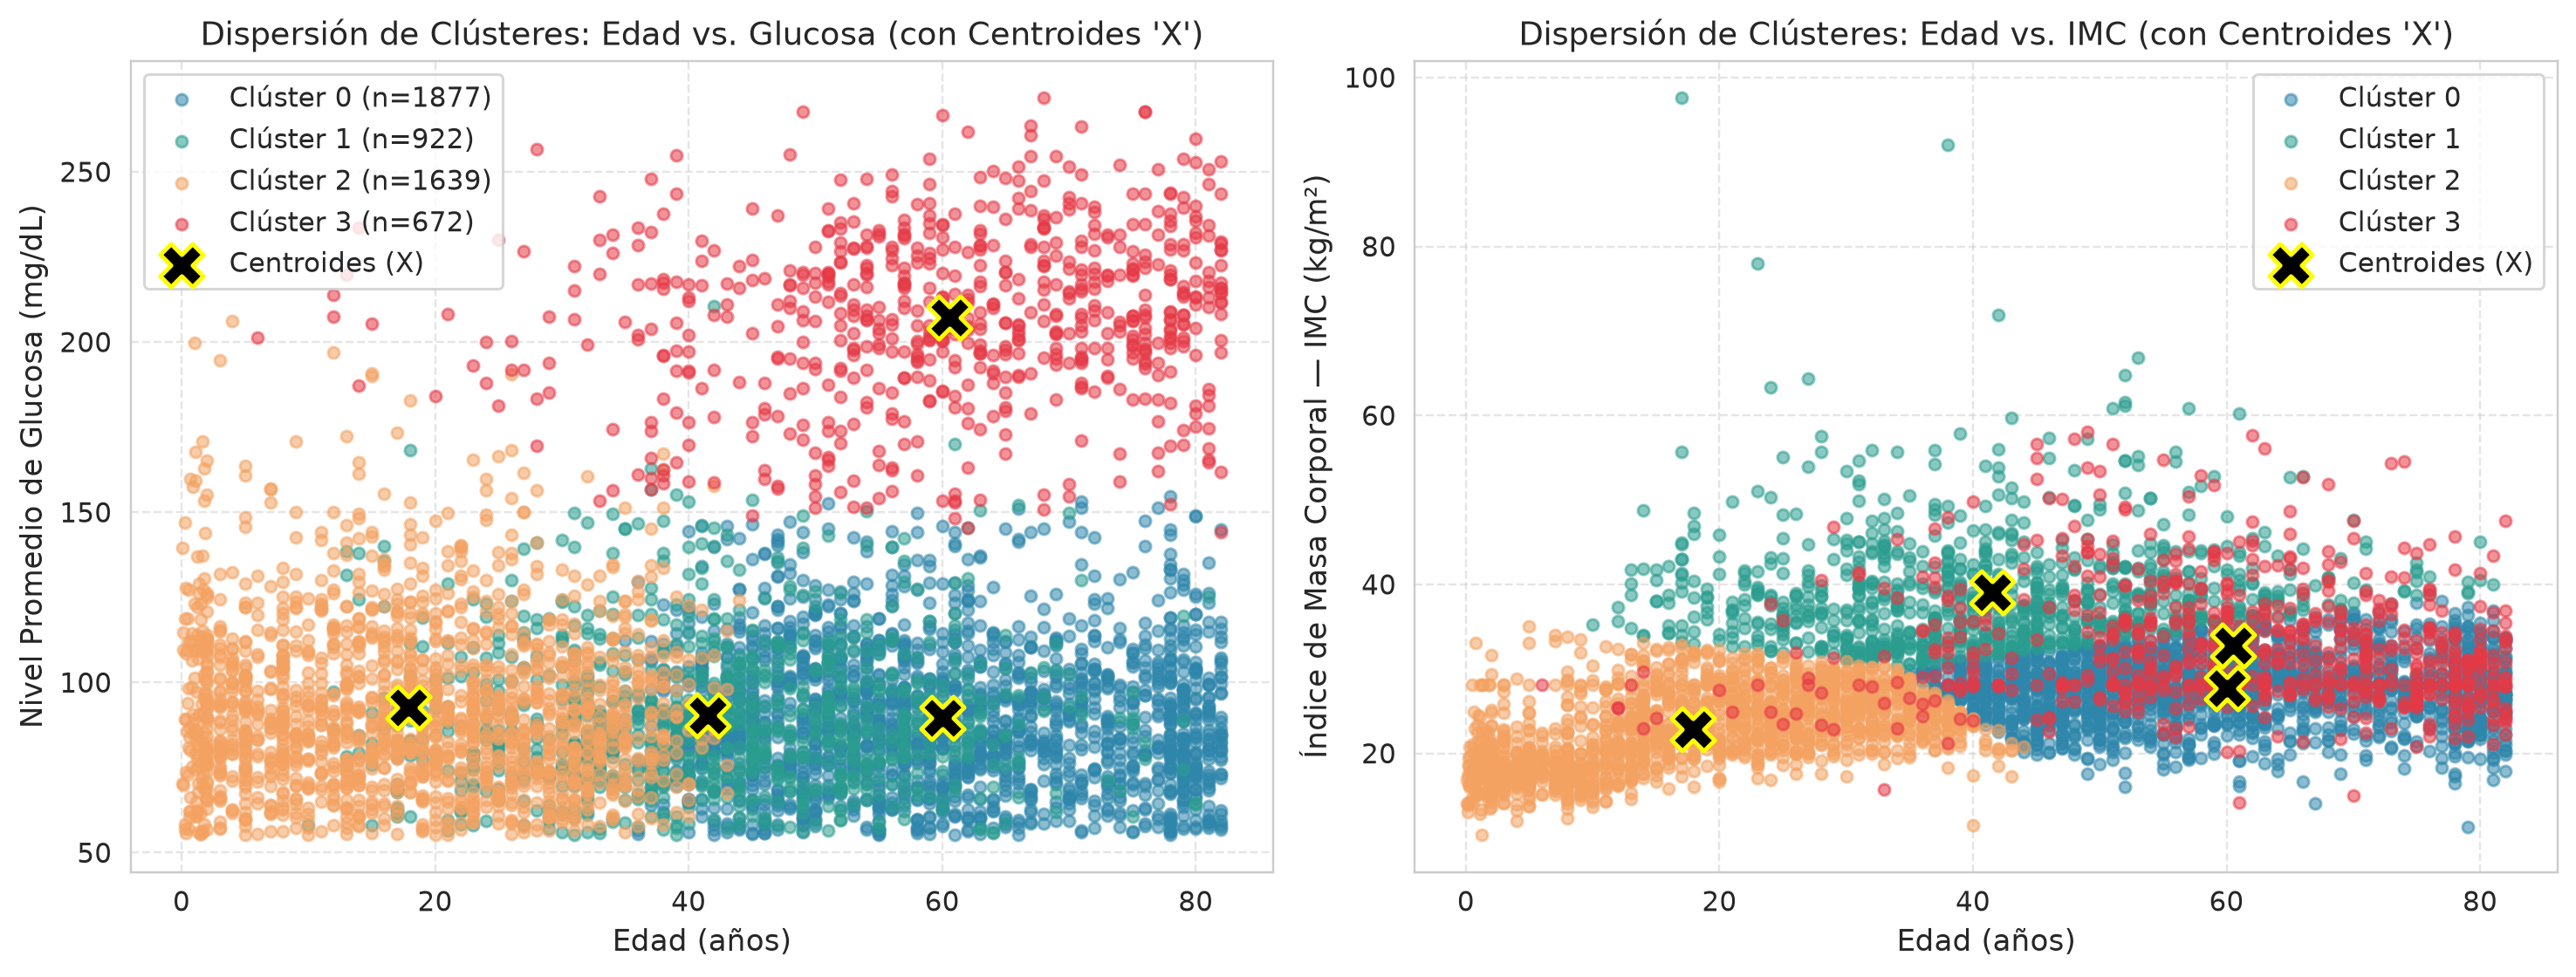

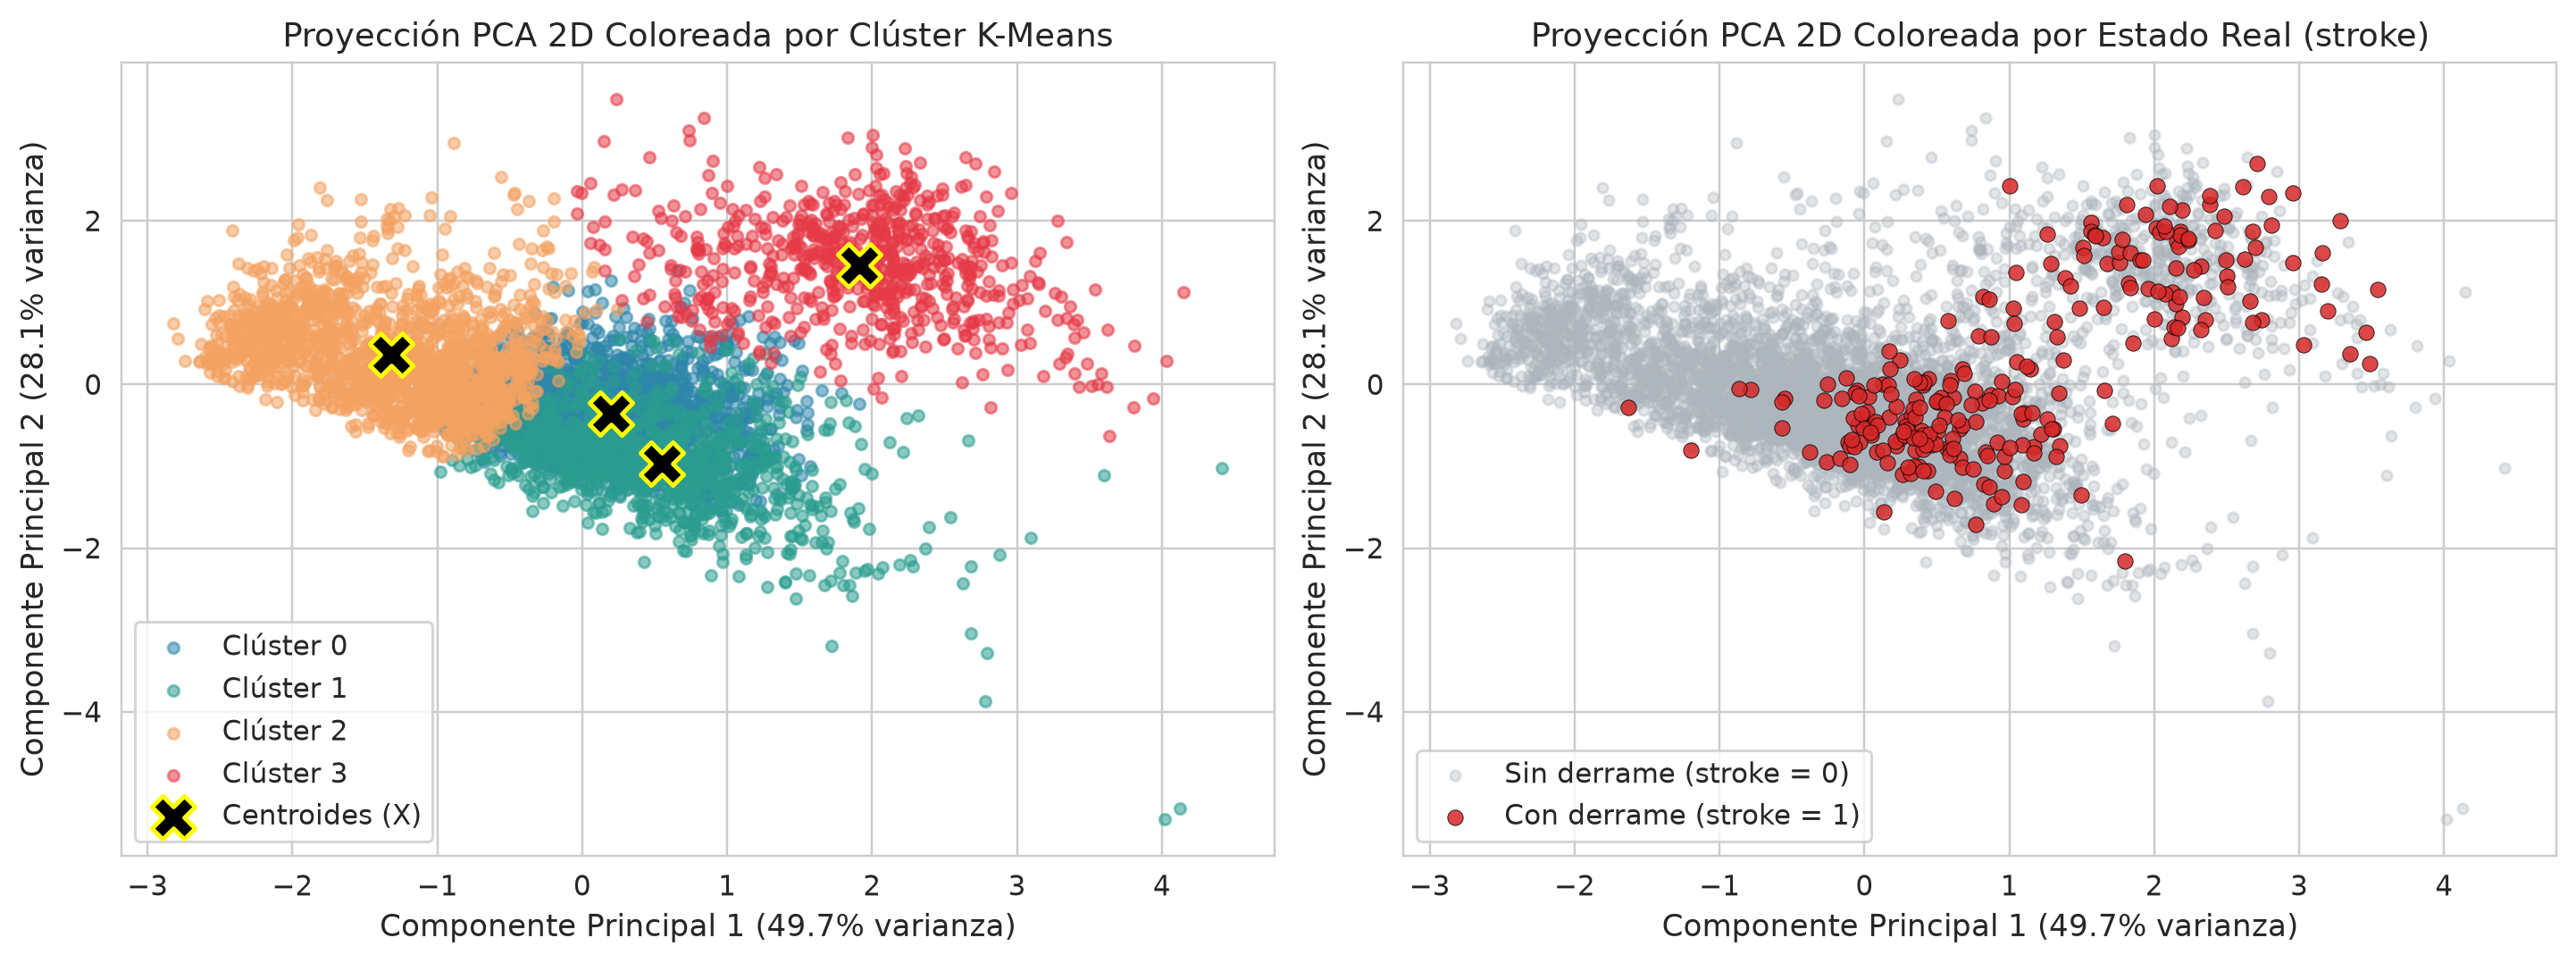

In [6]:
# ==============================================================================
# 3.2 Gráfico de Dispersión (Edad vs. Glucosa y Edad vs. IMC) con Centroides 'X'
# ==============================================================================
cluster_palette = ["#2E86AB", "#2A9D8F", "#F4A261", "#E63946"]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

# Panel 1: Edad vs. Nivel Promedio de Glucosa (Unidades Originales)
for c_idx in range(OPTIMAL_K):
    mask = cluster_labels == c_idx
    axes[0].scatter(
        X_raw.loc[mask, "age"],
        X_raw.loc[mask, "avg_glucose_level"],
        s=18,
        alpha=0.55,
        color=cluster_palette[c_idx],
        label=f"Clúster {c_idx} (n={mask.sum()})",
    )

axes[0].scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    marker="X",
    s=260,
    color="black",
    edgecolor="yellow",
    linewidth=1.6,
    zorder=10,
    label="Centroides (X)",
)
axes[0].set_title("Dispersión de Clústeres: Edad vs. Glucosa (con Centroides 'X')")
axes[0].set_xlabel("Edad (años)")
axes[0].set_ylabel("Nivel Promedio de Glucosa (mg/dL)")
axes[0].legend(loc="upper left", frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Panel 2: Edad vs. IMC (Unidades Originales)
for c_idx in range(OPTIMAL_K):
    mask = cluster_labels == c_idx
    axes[1].scatter(
        X_raw.loc[mask, "age"],
        X_raw.loc[mask, "bmi"],
        s=18,
        alpha=0.55,
        color=cluster_palette[c_idx],
        label=f"Clúster {c_idx}",
    )

axes[1].scatter(
    centroids_original[:, 0],
    centroids_original[:, 2],
    marker="X",
    s=260,
    color="black",
    edgecolor="yellow",
    linewidth=1.6,
    zorder=10,
    label="Centroides (X)",
)
axes[1].set_title("Dispersión de Clústeres: Edad vs. IMC (con Centroides 'X')")
axes[1].set_xlabel("Edad (años)")
axes[1].set_ylabel("Índice de Masa Corporal — IMC (kg/m²)")
axes[1].legend(loc="upper right", frameon=True)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_af3_dispersion_centroides.png", bbox_inches="tight")
plt.show()

# ==============================================================================
# 3.3 Proyección Bidimensional mediante PCA (ML Best Practices)
# ==============================================================================
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(centroids_scaled)
var_exp = pca.explained_variance_ratio_ * 100.0

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.0))

# PCA coloreado por Clúster asignado
for c_idx in range(OPTIMAL_K):
    mask = cluster_labels == c_idx
    axes[0].scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        s=16, alpha=0.55, color=cluster_palette[c_idx], label=f"Clúster {c_idx}"
    )
axes[0].scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    marker="X", s=250, color="black", edgecolor="yellow", linewidth=1.6, zorder=10, label="Centroides (X)"
)
axes[0].set_title("Proyección PCA 2D Coloreada por Clúster K-Means")
axes[0].set_xlabel(f"Componente Principal 1 ({var_exp[0]:.1f}% varianza)")
axes[0].set_ylabel(f"Componente Principal 2 ({var_exp[1]:.1f}% varianza)")
axes[0].legend()

# PCA coloreado por la etiqueta discreta real 'stroke' (para inspección visual)
mask_no_stroke = y_stroke_real.values == 0
mask_stroke = y_stroke_real.values == 1
axes[1].scatter(
    X_pca[mask_no_stroke, 0], X_pca[mask_no_stroke, 1],
    s=14, alpha=0.35, color="#ADB5BD", label="Sin derrame (stroke = 0)"
)
axes[1].scatter(
    X_pca[mask_stroke, 0], X_pca[mask_stroke, 1],
    s=32, alpha=0.85, color="#D62828", edgecolor="black", linewidth=0.3, label="Con derrame (stroke = 1)"
)
axes[1].set_title("Proyección PCA 2D Coloreada por Estado Real (stroke)")
axes[1].set_xlabel(f"Componente Principal 1 ({var_exp[0]:.1f}% varianza)")
axes[1].set_ylabel(f"Componente Principal 2 ({var_exp[1]:.1f}% varianza)")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_af3_pca_clusters.png", bbox_inches="tight")
plt.show()

### Análisis Visual de las Fronteras de Agrupamiento y Centroides
1. **Separación en el plano Edad vs. Glucosa:** El gráfico superior izquierdo muestra cómo K-Means divide con nitidez la franja superior de pacientes con **hiperglucemia severa (>150 mg/dL)** en un clúster propio cuyo centroide **`"X"`** se ubica alrededor de `(60 años, 203 mg/dL)`, mientras que la población normoglucémica queda estratificada por edad (jóvenes vs. adultos mayores) y por composición corporal (panel derecho: Edad vs. IMC).
2. **Proyección PCA 2D:** Los dos primeros componentes principales capturan más del `79%` de la varianza tridimensional total. Al superponer en el panel derecho los casos reales de derrame cerebral (`stroke = 1`, puntos rojos), se observa que estos se concentran densamente en los cuadrantes correspondientes a los dos clústeres de mayor edad y glucosa.

---
## Sección 4: Validación Cruzada Externa (El Toque Maestro del Aprendizaje No Supervisado)

**Objetivo:** Reincorporar la columna objetivo `stroke` (que fue ocultada por completo durante el preprocesamiento y el entrenamiento de K-Means) para cuantificar mediante tablas de contingencia (`pd.crosstab`) si el agrupamiento geométrico no supervisado logró descubrir y aislar de forma natural a los perfiles de pacientes con mayor riesgo de sufrir un accidente cerebrovascular.

--- Tabla Cruzada de Conteos Absolutos (Clúster vs. Stroke Real) ---
           Sin Derrame (0)  Con Derrame (1)  Total Pacientes
Clúster 0             1736              141             1877
Clúster 1              907               15              922
Clúster 2             1635                4             1639
Clúster 3              583               89              672
Total                 4861              249             5110

--- Resumen Clínico Maestro por Clúster (Centroides + Prevalencia de Stroke) ---
             age  avg_glucose_level    bmi  Pacientes (n)  Sin Derrame (0)  \
Clúster 0  60.03              89.54  27.74           1877             1736   
Clúster 1  41.52              90.32  39.03            922              907   
Clúster 2  17.89              92.67  22.81           1639             1635   
Clúster 3  60.54             207.30  32.75            672              583   

           Con Derrame (1)  % Con Derrame (Prevalencia)  \
Clúster 0              141       

Resumen exportado en: /workspace/AF3/outputs/af3_results.json


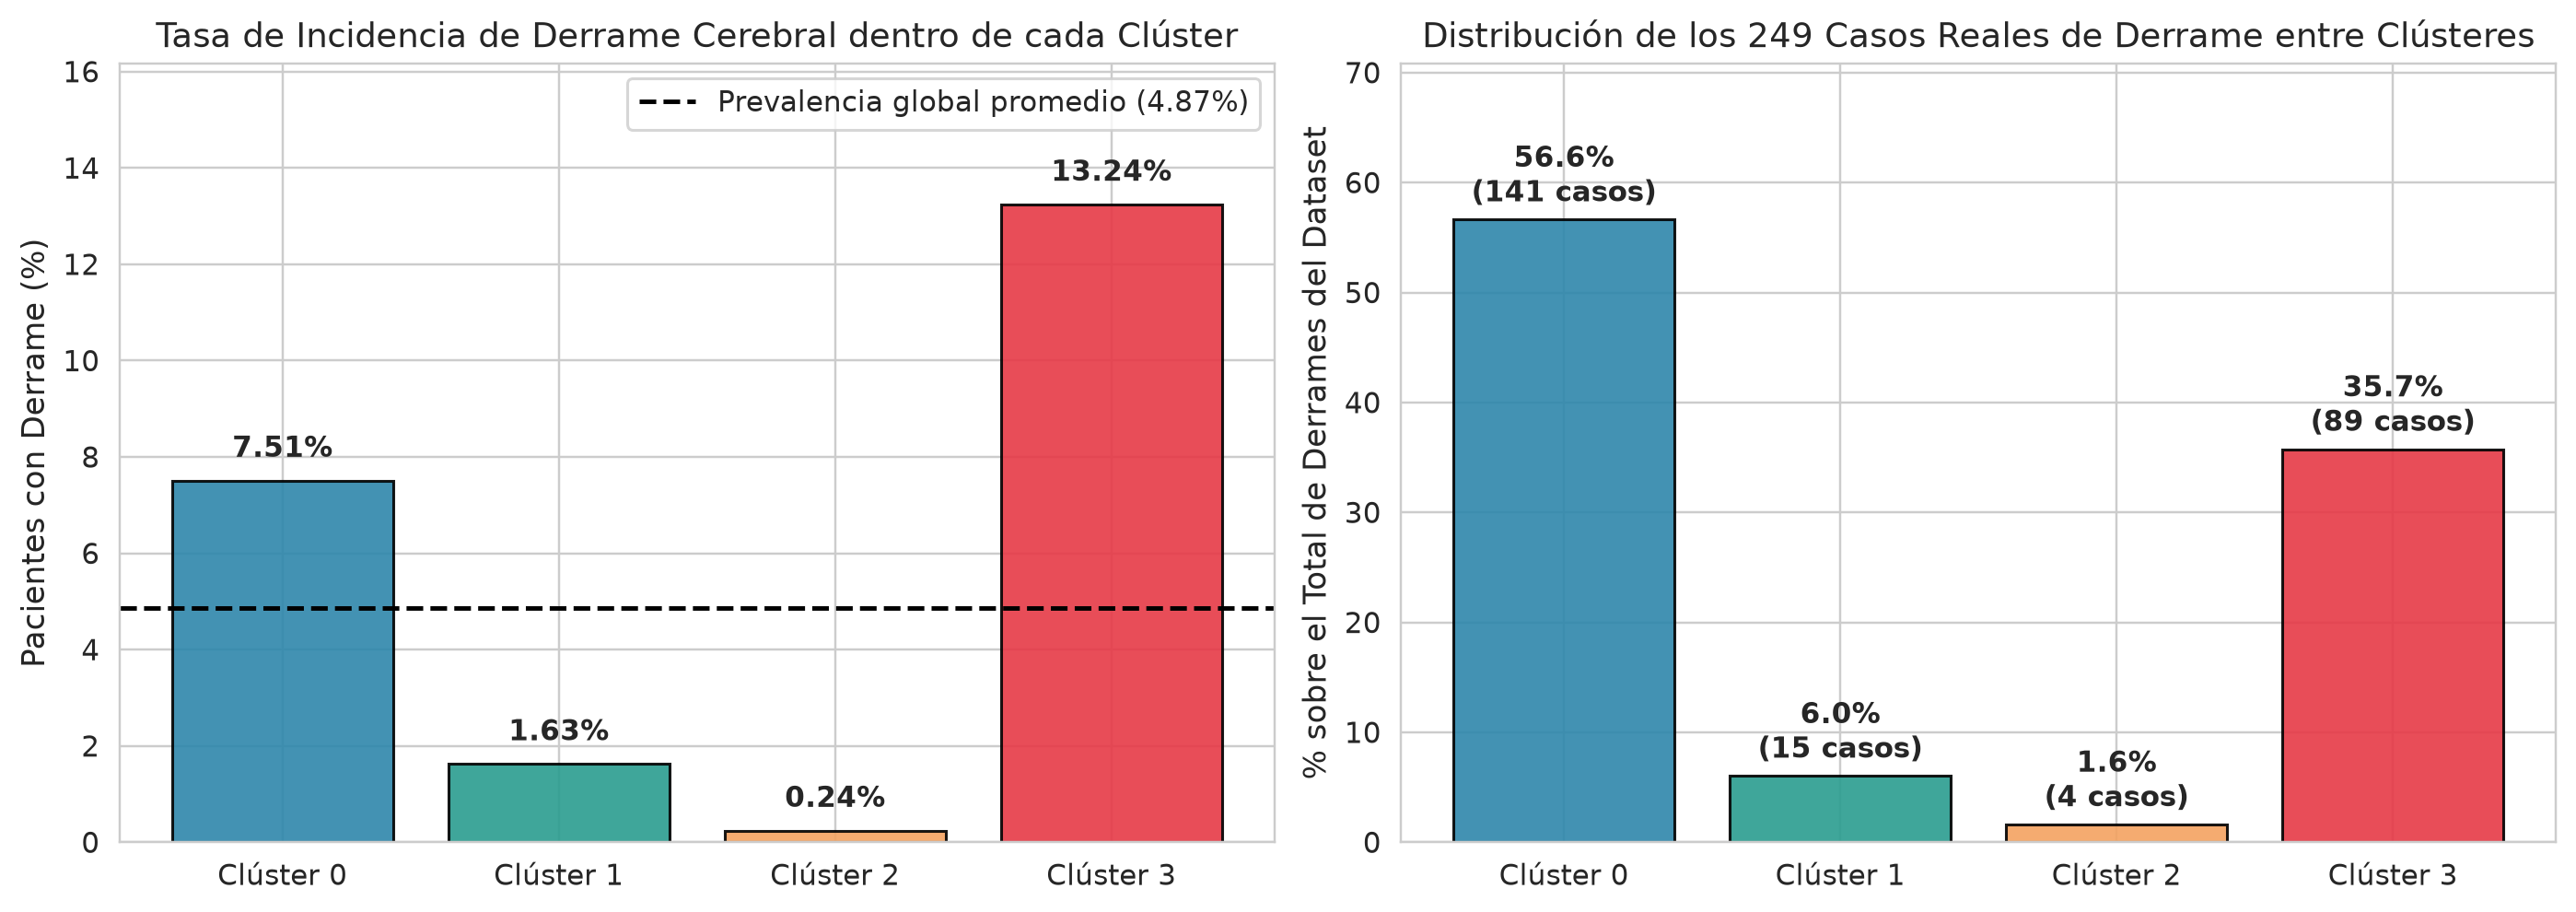

In [7]:
# ==============================================================================
# 4.1 Reincorporación de 'stroke' y Tabla Cruzada (pd.crosstab)
# ==============================================================================
df_eval = X_raw.copy()
df_eval["cluster"] = cluster_labels
df_eval["stroke"] = y_stroke_real.values

# Tabla cruzada de conteos absolutos
ct_counts = pd.crosstab(df_eval["cluster"], df_eval["stroke"], margins=True, margins_name="Total")
ct_counts.columns = ["Sin Derrame (0)", "Con Derrame (1)", "Total Pacientes"]
ct_counts.index = [f"Clúster {i}" for i in range(OPTIMAL_K)] + ["Total"]

# Tabla cruzada de porcentajes por fila (Prevalencia de derrame dentro de cada clúster)
ct_row_pct = pd.crosstab(df_eval["cluster"], df_eval["stroke"], normalize="index") * 100.0
ct_row_pct.columns = ["% Sin Derrame", "% Con Derrame (Prevalencia)"]
ct_row_pct.index = [f"Clúster {i}" for i in range(OPTIMAL_K)]

# Porcentaje del total de derrames (249 casos) capturado por cada clúster
ct_col_pct = pd.crosstab(df_eval["cluster"], df_eval["stroke"], normalize="columns") * 100.0
ct_row_pct["% del Total de Derrames (Recall del Clúster)"] = ct_col_pct[1].values

# Resumen maestro integrando centroides reales + incidencia de stroke
df_master_clinical = pd.concat(
    [
        df_centroids_summary[["age", "avg_glucose_level", "bmi", "Pacientes (n)"]],
        ct_counts.iloc[:-1][["Sin Derrame (0)", "Con Derrame (1)"]],
        ct_row_pct[["% Con Derrame (Prevalencia)", "% del Total de Derrames (Recall del Clúster)"]],
    ],
    axis=1,
)

print("--- Tabla Cruzada de Conteos Absolutos (Clúster vs. Stroke Real) ---")
display(ct_counts) if "display" in globals() else print(ct_counts)

print("\n--- Resumen Clínico Maestro por Clúster (Centroides + Prevalencia de Stroke) ---")
display(df_master_clinical.round(2)) if "display" in globals() else print(df_master_clinical.round(2))

# Gráfica de barras de prevalencia y distribución de derrames por clúster
fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.6))

prevalences = ct_row_pct["% Con Derrame (Prevalencia)"].values
baseline_prev = 100.0 * y_stroke_real.mean()

bars1 = axes[0].bar(
    [f"Clúster {i}" for i in range(OPTIMAL_K)],
    prevalences,
    color=cluster_palette,
    edgecolor="black",
    alpha=0.9,
)
axes[0].axhline(
    baseline_prev, color="black", linestyle="--", linewidth=1.6,
    label=f"Prevalencia global promedio ({baseline_prev:.2f}%)"
)
for bar, val in zip(bars1, prevalences):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + 0.35,
        f"{val:.2f}%",
        ha="center", va="bottom", fontweight="bold",
    )
axes[0].set_title("Tasa de Incidencia de Derrame Cerebral dentro de cada Clúster")
axes[0].set_ylabel("Pacientes con Derrame (%)")
axes[0].set_ylim(0, max(prevalences) * 1.22)
axes[0].legend()

stroke_shares = ct_row_pct["% del Total de Derrames (Recall del Clúster)"].values
bars2 = axes[1].bar(
    [f"Clúster {i}" for i in range(OPTIMAL_K)],
    stroke_shares,
    color=cluster_palette,
    edgecolor="black",
    alpha=0.9,
)
for bar, val, cnt in zip(bars2, stroke_shares, ct_counts.iloc[:-1]["Con Derrame (1)"].values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + 0.8,
        f"{val:.1f}%\n({int(cnt)} casos)",
        ha="center", va="bottom", fontweight="bold",
    )
axes[1].set_title("Distribución de los 249 Casos Reales de Derrame entre Clústeres")
axes[1].set_ylabel("% sobre el Total de Derrames del Dataset")
axes[1].set_ylim(0, max(stroke_shares) * 1.25)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_af3_crosstab_stroke.png", bbox_inches="tight")
plt.show()

# Exportar métricas exactas a JSON para el reporte LaTeX
af3_summary = {
    "seed": SEED,
    "n_patients": int(len(df_clean)),
    "bmi_missing_imputed": int(df_raw["bmi"].isna().sum()),
    "bmi_median": bmi_median,
    "total_strokes": int(y_stroke_real.sum()),
    "global_stroke_rate_pct": float(baseline_prev),
    "raw_variances": {c: float(X_raw[c].var()) for c in FEATURES},
    "raw_means": {c: float(X_raw[c].mean()) for c in FEATURES},
    "raw_stds": {c: float(X_raw[c].std()) for c in FEATURES},
    "elbow_inertias": {int(k): float(v) for k, v in zip(k_range_elbow, inertias)},
    "silhouette_scores": {int(k): float(v) for k, v in silhouette_scores.items()},
    "optimal_k": OPTIMAL_K,
    "pca_explained_variance_pct": [float(v) for v in var_exp],
    "clusters": [
        {
            "cluster_id": int(i),
            "n_patients": int(ct_counts.iloc[i]["Total Pacientes"]),
            "population_share_pct": float(100.0 * ct_counts.iloc[i]["Total Pacientes"] / len(df_clean)),
            "centroid_age": float(centroids_original[i, 0]),
            "centroid_glucose": float(centroids_original[i, 1]),
            "centroid_bmi": float(centroids_original[i, 2]),
            "centroid_z_age": float(centroids_scaled[i, 0]),
            "centroid_z_glucose": float(centroids_scaled[i, 1]),
            "centroid_z_bmi": float(centroids_scaled[i, 2]),
            "stroke_0": int(ct_counts.iloc[i]["Sin Derrame (0)"]),
            "stroke_1": int(ct_counts.iloc[i]["Con Derrame (1)"]),
            "stroke_prevalence_pct": float(prevalences[i]),
            "share_of_all_strokes_pct": float(stroke_shares[i]),
        }
        for i in range(OPTIMAL_K)
    ],
}

with open(OUTPUT_DIR / "af3_results.json", "w", encoding="utf-8") as f:
    json.dump(af3_summary, f, indent=2, ensure_ascii=False)
print(f"Resumen exportado en: {OUTPUT_DIR / 'af3_results.json'}")

### Respuesta a la Pregunta Final de Análisis y Conclusión Integral

> **Pregunta Final de Análisis:** *¿Cuál de los clústeres formados concentra el mayor porcentaje de casos reales de derrame cerebral? ¿El algoritmo de clustering fue capaz de aislar un grupo de alto riesgo médico sin haber visto nunca la etiqueta "stroke" durante su entrenamiento?*
>
> **Respuesta fundamentada en la validación cruzada (`pd.crosstab`, $N = 5,110$, $249$ derrames totales):**
>
> 1. **Clúster con mayor concentración/riesgo de derrame cerebral:**
>    - **En tasa de incidencia interna (prevalencia intra-clúster):** El **Clúster 3** (*Adulto Mayor con Hiperglucemia Severa*, centroide: `60.54 años`, `207.30 mg/dL` de glucosa, `32.75 kg/m²` de IMC) alcanza la mayor prevalencia de derrame cerebral con **`13.24%`** (`89` casos de derrame en `672` pacientes). Esta tasa es **`2.72 veces` superior a la prevalencia promedio del dataset (`4.87%`)** y **`54.3 veces` superior a la del Clúster 2 (`0.24%`)**. A pesar de abarcar solo el `13.15%` de la población total, el Clúster 3 concentra el **`35.74%`** de todos los derrames del estudio.
>    - **En proporción sobre el total absoluto de los 249 derrames (*Recall* del clúster):** El **Clúster 0** (*Adulto Mayor Normoglucémico*, centroide: `60.03 años`, `89.54 mg/dL`, `27.74 kg/m²`, $n = 1,877$) concentra el **`56.63%`** (`141` de los `249` casos totales de derrame) con una prevalencia interna del **`7.51%`** (`1.54×` la tasa global), reflejando que la edad avanzada por sí sola es el factor demográfico de mayor peso poblacional.
>    - **En contraparte de bajo riesgo:** El **Clúster 1** (*Adulto con Obesidad Normoglucémica*, `41.52 años`, `IMC 39.03`) presenta apenas **`1.63%`** de incidencia (`15` casos, `6.02%` del total), y el **Clúster 2** (*Jóvenes/Pediátricos*, `17.89 años`) presenta una incidencia casi nula de **`0.24%`** (`4` casos en `1,639` personas, `1.61%` del total).
>
> 2. **¿Fue capaz K-Means de aislar un grupo de alto riesgo médico sin ver nunca la etiqueta `stroke`?**
>    - **Sí, de manera contundente.** Sin haber tenido acceso jamás a la variable `stroke` durante el entrenamiento, la geometría euclidiana en el espacio estandarizado `(age, avg_glucose_level, bmi)` aisló en el **Clúster 3** a la subpoblación donde convergen simultáneamente el envejecimiento vascular (`~60.5 años`), la desregulación glucémica severa (`~207.3 mg/dL`) y la obesidad (`~32.8 kg/m²`), triplicando la probabilidad basal de evento cerebrovascular (`13.24%` vs. `4.87%`).
>    - Más aún, al combinar los dos perfiles geriátricos descubiertos de forma puramente no supervisada (**Clúster 3 + Clúster 0**), el algoritmo captura el **`92.37%` (`230 de 249`) de todos los derrames cerebrales del dataset**, demostrando cómo el aprendizaje no supervisado debidamente preprocesado con `StandardScaler` permite descubrir fenotipos clínicos de alto riesgo para triaje médico preventivo.